# L15 — Object Detection: Sliding Windows, R-CNN, YOLO — Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L15-ObjectDetection/L15_Object_Detection.ipynb)

This notebook accompanies **Lecture 15**. L12–L14 answered *"what is in this picture?"* with one label.
A **detector** answers *"what is where?"*: a list of boxes, each with a label and a score.

1. **What a detector outputs, and how we score it**: boxes, IoU, a sliding window, non-maximum suppression,
   precision and recall.
2. **Two-stage detectors** (R-CNN, Fast R-CNN, Faster R-CNN): propose likely regions, then classify each.
3. **One-stage detectors** (YOLO): one pass of one network predicts every box at once.

Our data is a 1950 oblique air photo of a **cabin court** (Paul Sharpe collection, the same collection as the
oblique projects). Its 26 cabins have hand-drawn boxes, so every detector today can be checked against the truth.
We also use a 1948 photo of a Ford garage with three parked cars.

Everything runs on a CPU in about 4 minutes; most of that is §9 (fine-tuning YOLO, about 2 minutes).
On Colab a GPU makes §9 faster but is not needed.

| Section | Topic |
|---------|-------|
| 0 | Setup and data |
| 1 | Boxes: what a detector outputs |
| 2 | IoU: how much do two boxes overlap? |
| 3 | A sliding window: template matching, checked on a made-up scene |
| 4 | The sliding window on the cabin court, and non-maximum suppression |
| 5 | Precision and recall |
| 6 | Two-stage detectors: Faster R-CNN in one line, anchors and RoI pooling by hand |
| 7 | YOLO: the output grid, and a trained YOLO on the 1948 garage |
| 8 | YOLO on the cabins: right boxes, wrong label |
| 9 | Fine-tuning YOLO on 12 labelled cabins (the L14 recipe for detectors) |
| 10 | The three detectors side by side |
| 11 | Try at home |

In [2]:
import json, os, time
os.environ["YOLO_VERBOSE"] = "False"          # keep the ultralytics package quiet (set before importing it)
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 0 · Setup and data

`L15.zip` (3.5 MB) holds two crops of Paul Sharpe's oblique photos and the hand-drawn cabin boxes.
The trained YOLO weights (`yolo11n.pt`, 5.6 MB) are downloaded by the `ultralytics` package in §7.
Safe to re-run.

In [3]:
import io, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("L15.zip", ["L15/court.png", "L15/garage.png", "L15/cabins_gt.json"])
court = cv2.imread("L15/court.png", cv2.IMREAD_GRAYSCALE)        # 1950 cabin court, 1400 x 422
garage = cv2.imread("L15/garage.png")                            # 1948 Ford garage (BGR), 1800 x 1100
GT = np.array(json.load(open("L15/cabins_gt.json"))["boxes"])    # 26 cabins, (x1, y1, x2, y2)
print("court", court.shape, "| garage", garage.shape, "| cabins", len(GT))

L15.zip: already present
court (422, 1400) | garage (1100, 1800, 3) | cabins 26


In [4]:
try:
    import ultralytics
except ImportError:                       # Colab: install once (about 30 s)
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    import ultralytics
print("ultralytics", ultralytics.__version__)

ultralytics 8.4.203


## 1 · Boxes: what a detector outputs

A classifier returns one label for the whole image. A detector returns a **list**; each entry is

* a **box**: 4 numbers,
* a **label** (cabin, car, …),
* a **score** between 0 and 1 (how sure it is).

Boxes come in two common formats. **Corners**: (x1, y1, x2, y2), top-left and bottom-right, in pixels with
y pointing **down**. **Centre and size**: (cx, cy, w, h). YOLO's label files use centre and size, divided by
the image width and height so every number is between 0 and 1.

In [5]:
def corners_to_cxcywh(b):
    x1, y1, x2, y2 = b
    return ((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1)

def cxcywh_to_corners(b):
    cx, cy, w, h = b
    return (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)

print("cabin 17 corners:", tuple(GT[17]), "-> centre/size:", corners_to_cxcywh(GT[17]))
print("slide 'your turn':  (100, 50, 40, 20) -> corners:", cxcywh_to_corners((100, 50, 40, 20)))
H, W = court.shape
cx, cy, w, h = corners_to_cxcywh(GT[17])
print(f"YOLO label line for cabin 17:  0 {cx/W:.4f} {cy/H:.4f} {w/W:.4f} {h/H:.4f}")

cabin 17 corners: (np.int64(889), np.int64(223), np.int64(956), np.int64(278)) -> centre/size: (np.float64(922.5), np.float64(250.5), np.int64(67), np.int64(55))
slide 'your turn':  (100, 50, 40, 20) -> corners: (80.0, 40.0, 120.0, 60.0)
YOLO label line for cabin 17:  0 0.6589 0.5936 0.0479 0.1303


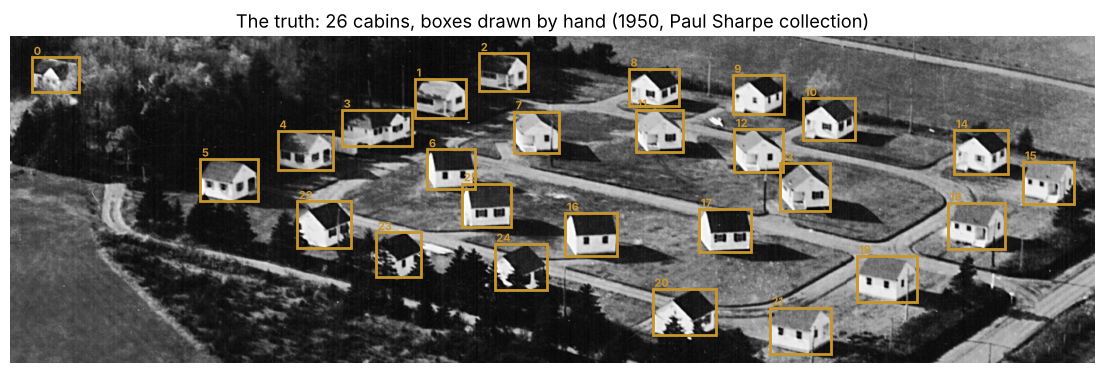

In [6]:
def draw_boxes(ax, boxes, col, lw=1.8, labels=None):
    for i, b in enumerate(boxes):
        x1, y1, x2, y2 = b[:4]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=col, lw=lw))
        if labels is not None:
            ax.text(x1 + 2, y1 - 3, labels[i], color=col, fontsize=8, fontweight="bold")

fig, ax = plt.subplots(figsize=(14, 4.6))
ax.imshow(court, cmap="gray"); ax.axis("off")
draw_boxes(ax, GT, GOLD, 2, labels=[str(i) for i in range(len(GT))])
ax.set_title("The truth: 26 cabins, boxes drawn by hand (1950, Paul Sharpe collection)")
plt.show()

## 2 · IoU: how much do two boxes overlap?

**Intersection over union**: the area both boxes share, divided by the area either one covers.
1 = the same box, 0 = no overlap. A predicted box usually **counts as correct if IoU ≥ 0.5** with a true box.

In [7]:
def area(b):
    return max(0, b[2] - b[0]) * max(0, b[3] - b[1])

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))     # overlap width
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))     # overlap height
    inter = ix * iy
    return inter / (area(a) + area(b) - inter)

print("slide example  A=(0,0,4,4), B=(2,2,6,6):", round(iou((0, 0, 4, 4), (2, 2, 6, 6)), 3), " = 4/28")
print("your turn      A=(0,0,4,4), B=(1,0,5,4):", round(iou((0, 0, 4, 4), (1, 0, 5, 4)), 3), " = 12/20")
b = GT[17]; shifted = b + np.array([10, 0, 10, 0])
print(f"cabin 17 ({b[2]-b[0]} x {b[3]-b[1]} px) vs the same box 10 px to the right:", round(iou(b, shifted), 3))
for dx in [20, 30, 40]:
    print(f"   shifted {dx} px: IoU {iou(b, b + np.array([dx, 0, dx, 0])):.2f}")

slide example  A=(0,0,4,4), B=(2,2,6,6): 0.143  = 4/28
your turn      A=(0,0,4,4), B=(1,0,5,4): 0.6  = 12/20
cabin 17 (67 x 55 px) vs the same box 10 px to the right: 0.74
   shifted 20 px: IoU 0.54
   shifted 30 px: IoU 0.38
   shifted 40 px: IoU 0.25


A box that is off by 10 px on a 67 px cabin still has IoU 0.74. Shifted by half its width (about 33 px),
IoU drops below 0.5 and the box no longer counts.

## 3 · A sliding window: template matching, checked on a made-up scene

The oldest detector: take a **classifier** (here the simplest one: "how much does this patch look like
my example cabin?") and run it at **every position**. `cv2.matchTemplate` does exactly that: it slides the
template over the image and returns a score for every window (normalised cross-correlation, from L7:
1 = identical up to brightness and contrast).

**How many windows?** For an image W × H, a window w × h and a step (stride) s:

$$\left(\frac{W-w}{s}+1\right)\times\left(\frac{H-h}{s}+1\right)$$

In [8]:
def n_windows(W, H, w, h, s):
    return ((W - w) // s + 1) * ((H - h) // s + 1)

print("slide example: 640 x 480 image, 64 x 64 window, stride 16:", n_windows(640, 480, 64, 64, 16))
print("               ... at 4 window sizes, about", 4 * n_windows(640, 480, 64, 64, 16))
TI = 22                                              # our one example cabin (left half of the court)
x1, y1, x2, y2 = GT[TI]; T = court[y1:y2, x1:x2]
th, tw = T.shape
print(f"template = cabin {TI}: {tw} x {th} px")
print(f"court 1400 x 422, stride 1: {n_windows(1400, 422, tw, th, 1):,} windows")

slide example: 640 x 480 image, 64 x 64 window, stride 16: 999
               ... at 4 window sizes, about 3996
template = cabin 22: 70 x 60 px
court 1400 x 422, stride 1: 483,153 windows


**First, a scene where we know the answer.** We paste 8 copies of the template onto a plain grassy
background at known places, then slide the template over it. Every copy should score 1.0 and nothing else
should come close.

In [9]:
rng = np.random.default_rng(0)
grass = court[300:422, 0:200].astype(np.float32)          # bottom-left corner of the court: field, no cabins
scene = cv2.resize(grass, (700, 300)) + rng.normal(0, 6, (300, 700))
scene = np.clip(scene, 0, 255).astype(np.uint8)
truth = []
for (x, y) in [(30, 30), (180, 60), (340, 25), (520, 50), (60, 190), (230, 210), (400, 180), (580, 200)]:
    scene[y:y + th, x:x + tw] = T
    truth.append((x, y, x + tw, y + th))

res_sim = cv2.matchTemplate(scene, T, cv2.TM_CCOEFF_NORMED)
print("score map", res_sim.shape, "= one score per window position")
peaks = [res_sim[y, x] for (x, y, _, _) in truth]
print("score at the 8 true positions:", np.round(peaks, 3))
mask = np.ones_like(res_sim, bool)
for (x, y, _, _) in truth:
    mask[max(0, y - th // 2):y + th // 2, max(0, x - tw // 2):x + tw // 2] = False
print(f"best score anywhere else: {res_sim[mask].max():.2f}")

score map (241, 631) = one score per window position
score at the 8 true positions: [          1           1           1           1           1           1           1           1]
best score anywhere else: 0.59


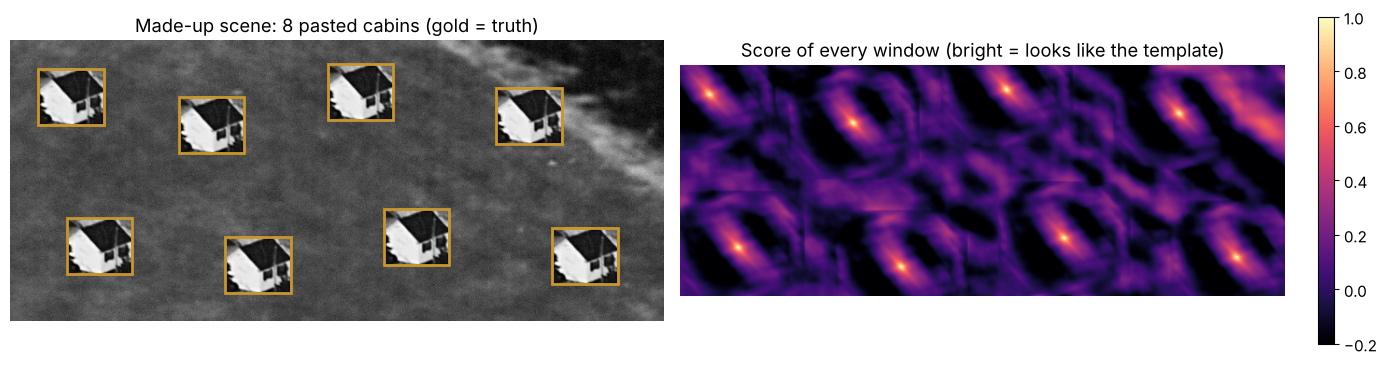

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].imshow(scene, cmap="gray"); draw_boxes(axes[0], truth, GOLD, 2)
axes[0].set_title("Made-up scene: 8 pasted cabins (gold = truth)"); axes[0].axis("off")
im = axes[1].imshow(res_sim, cmap="magma", vmin=-0.2, vmax=1)
axes[1].set_title("Score of every window (bright = looks like the template)"); axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.025)
plt.tight_layout(); plt.show()

## 4 · The sliding window on the cabin court, and non-maximum suppression

Now the real photo. The other 25 cabins are not copies of cabin 22: some face the other way, some are in
shadow, the nearer ones are bigger. Their scores are lower, and around every cabin **many neighbouring
windows** score almost as high as the best one.

483,153 windows scored; 20,300 score 0.3 or more


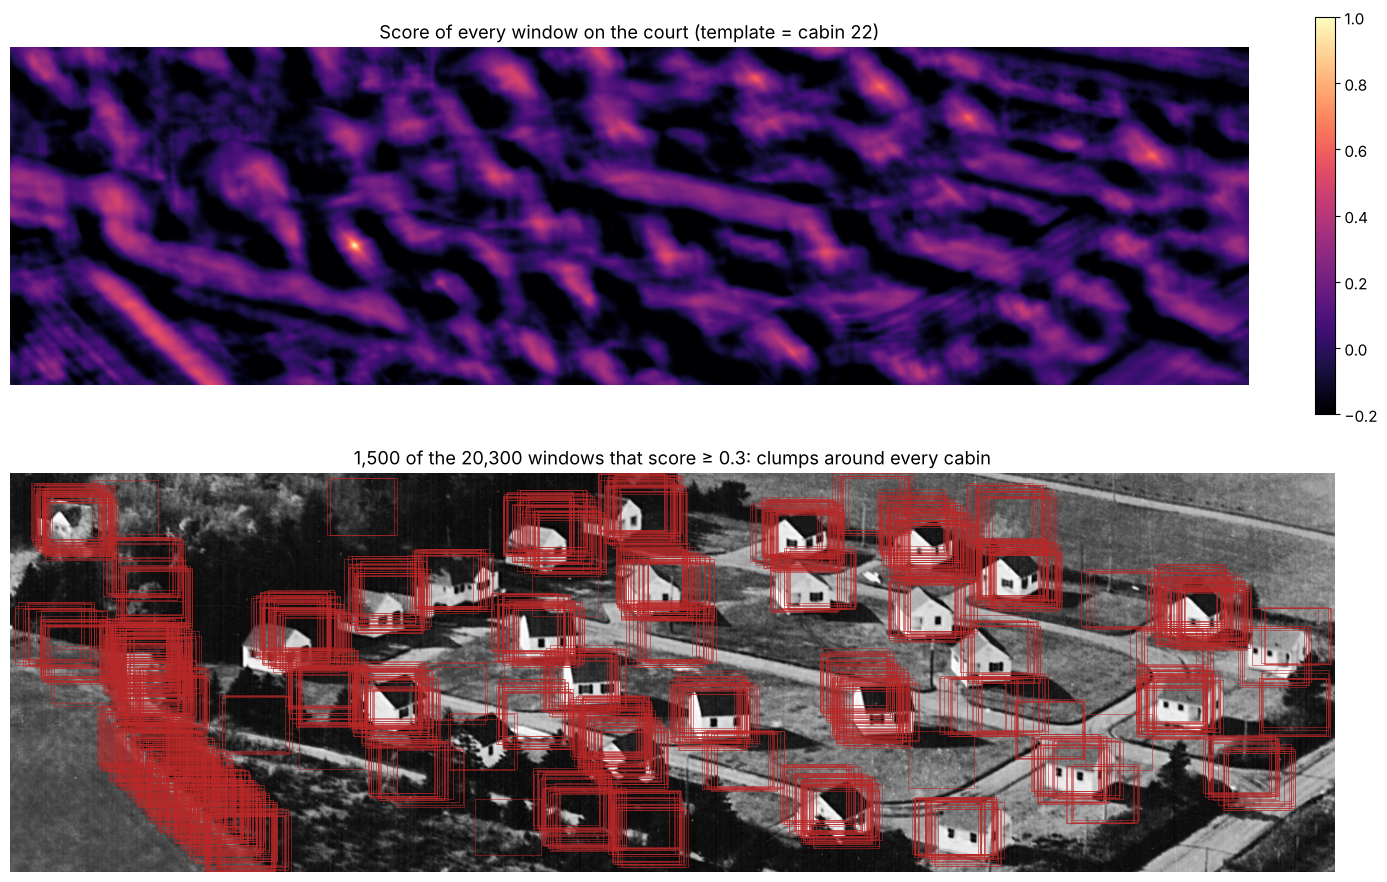

In [11]:
res = cv2.matchTemplate(court, T, cv2.TM_CCOEFF_NORMED)
ys, xs = np.where(res >= 0.3)
raw_scores = res[ys, xs]
raw_boxes = np.stack([xs, ys, xs + tw, ys + th], 1)
print(f"{res.size:,} windows scored; {len(raw_boxes):,} score 0.3 or more")

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
im = axes[0].imshow(res, cmap="magma", vmin=-0.2, vmax=1); axes[0].axis("off")
axes[0].set_title("Score of every window on the court (template = cabin 22)")
plt.colorbar(im, ax=axes[0], fraction=0.015)
axes[1].imshow(court, cmap="gray"); axes[1].axis("off")
sel = rng.choice(len(raw_boxes), 1500, replace=False)
draw_boxes(axes[1], raw_boxes[sel], RED, 0.4)
axes[1].set_title(f"1,500 of the {len(raw_boxes):,} windows that score ≥ 0.3: clumps around every cabin")
plt.tight_layout(); plt.show()

### Non-maximum suppression (NMS), by hand and in one line

Keep only the best box in each clump:

1. Sort the boxes by score.
2. Keep the best one. **Delete every other box that overlaps it with IoU above a threshold** (0.3 here).
3. Repeat with the best box that is left, until none are left.

The slide's worked example has four boxes:

In [12]:
def nms(boxes, scores, iou_thr):
    order = list(np.argsort(scores)[::-1])           # best first
    keep = []
    while order:
        best = order.pop(0)
        keep.append(best)
        order = [j for j in order if iou(boxes[best], boxes[j]) <= iou_thr]
    return keep

toy = np.array([[10, 10, 50, 40],      # A
                [14, 12, 54, 42],      # B: almost A
                [70, 15, 110, 45],     # C: another cabin
                [80, 18, 120, 48]])    # D: overlaps C
toy_s = np.array([0.9, 0.8, 0.75, 0.6])
for i, j in [(0, 1), (0, 2), (2, 3)]:
    print(f"IoU({'ABCD'[i]}, {'ABCD'[j]}) = {iou(toy[i], toy[j]):.2f}")
print("kept:", ["ABCD"[k] for k in nms(toy, toy_s, 0.3)])

IoU(A, B) = 0.72
IoU(A, C) = 0.00
IoU(C, D) = 0.51
kept: ['A', 'C']


In [13]:
t = time.time()
keep = nms(raw_boxes, raw_scores, 0.3)                           # our 8 lines (slow-ish in pure Python)
t_ours = time.time() - t
t = time.time()
keep_cv = cv2.dnn.NMSBoxes([[int(x1), int(y1), tw, th] for x1, y1, _, _ in raw_boxes],
                           raw_scores.tolist(), 0.3, 0.3)         # OpenCV, one line
t_cv = time.time() - t
keep_cv = np.array(keep_cv).ravel()
print(f"ours:   {len(raw_boxes):,} -> {len(keep)} boxes ({t_ours:.1f} s)")
print(f"OpenCV: {len(raw_boxes):,} -> {len(keep_cv)} boxes ({t_cv*1000:.0f} ms); same set: "
      f"{sorted(keep) == sorted(keep_cv.tolist())}")
dets_tm = sorted([(*raw_boxes[k], raw_scores[k]) for k in keep], key=lambda d: -d[4])

ours:   20,300 -> 76 boxes (0.8 s)
OpenCV: 20,300 -> 76 boxes (97 ms); same set: True


## 5 · Precision and recall

Match the detections to the truth, best score first: a detection is a **true positive (TP)** if it has
IoU ≥ 0.5 with a true box that is not already taken; otherwise it is a **false positive (FP)**. True boxes
left over are **misses (FN)**.

* **Precision** = TP / (number of detections): *of the boxes I drew, how many are cabins?*
* **Recall** = TP / (number of true objects): *of the cabins, how many did I find?*

Lowering the score threshold finds more cabins (recall up) but draws more wrong boxes (precision down).

In [14]:
def match(dets, truth, thr, iou_thr=0.5):
    # dets: (x1, y1, x2, y2, score), best first. Returns TP flags (per kept detection) and the missed truths.
    used, flags = set(), []
    for d in [d for d in dets if d[4] >= thr]:
        cands = [(iou(d, t), j) for j, t in enumerate(truth) if j not in used]
        best = max(cands) if cands else (0, None)
        ok = best[0] >= iou_thr
        if ok: used.add(best[1])
        flags.append(ok)
    return np.array(flags, bool), [j for j in range(len(truth)) if j not in used]

def pr(dets, truth, thr):
    f, _ = match(dets, truth, thr)
    tp = int(f.sum()); n = len(f)
    return n, tp, (tp / n if n else 1.0), tp / len(truth)

print(" thr   boxes  TP   precision  recall")
for thr in [0.6, 0.5, 0.45, 0.4, 0.35, 0.3]:
    n, tp, p, r = pr(dets_tm, GT, thr)
    print(f"{thr:4.2f}  {n:5d}  {tp:3d}   {p:8.2f}  {r:6.2f}")

 thr   boxes  TP   precision  recall
0.60      4    4       1.00    0.15
0.50     14    9       0.64    0.35
0.45     20   11       0.55    0.42
0.40     34   14       0.41    0.54
0.35     48   16       0.33    0.62
0.30     76   17       0.22    0.65


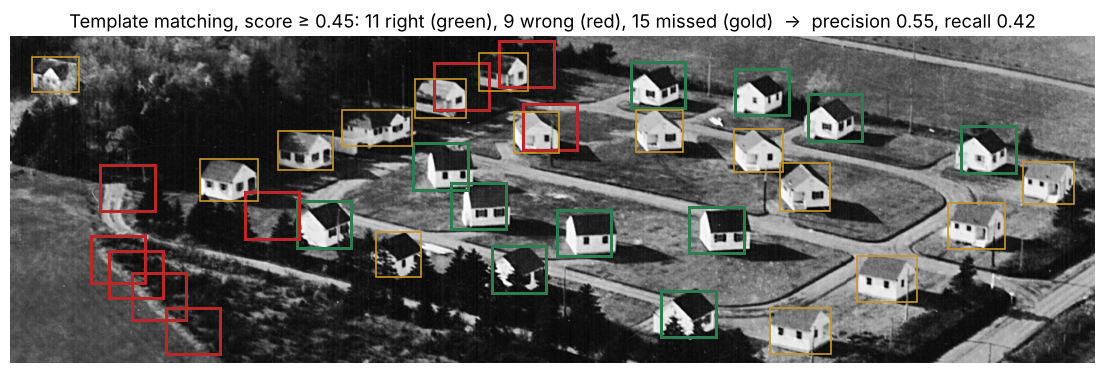

In [15]:
THR_TM = 0.45
flags, missed = match(dets_tm, GT, THR_TM)
kept = [d for d in dets_tm if d[4] >= THR_TM]
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.imshow(court, cmap="gray"); ax.axis("off")
draw_boxes(ax, [d for d, f in zip(kept, flags) if f], GREEN, 2.2)
draw_boxes(ax, [d for d, f in zip(kept, flags) if not f], RED, 2.2)
draw_boxes(ax, GT[missed], GOLD, 1.2)
n, tp, p, r = pr(dets_tm, GT, THR_TM)
ax.set_title(f"Template matching, score ≥ {THR_TM}: {tp} right (green), {n-tp} wrong (red), "
             f"{len(missed)} missed (gold)  →  precision {p:.2f}, recall {r:.2f}")
plt.show()

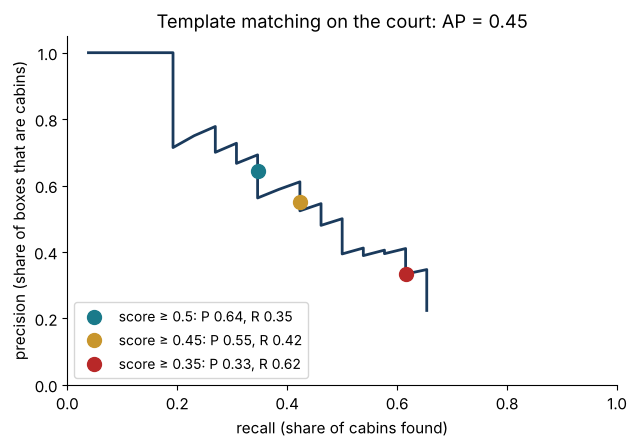

In [16]:
def pr_curve(dets, truth):
    s = np.array([d[4] for d in dets]); f, _ = match(dets, truth, -1)
    tp = np.cumsum(f); n = np.arange(1, len(f) + 1)
    return tp / len(truth), tp / n, s

def average_precision(rec, prec):
    # area under the precision-recall curve (precision made non-increasing first, as VOC/COCO do)
    p = np.maximum.accumulate(prec[::-1])[::-1]
    r = np.concatenate([[0], rec])
    return float(np.sum((r[1:] - r[:-1]) * p))

rec, prec, s = pr_curve(dets_tm, GT)
ap_tm = average_precision(rec, prec)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(rec, prec, color=NAVY, lw=2)
for thr, col in [(0.5, TEAL), (0.45, GOLD), (0.35, RED)]:
    n, tp, p, r = pr(dets_tm, GT, thr)
    ax.plot(r, p, "o", ms=10, color=col, label=f"score ≥ {thr}: P {p:.2f}, R {r:.2f}")
ax.set_xlabel("recall (share of cabins found)"); ax.set_ylabel("precision (share of boxes that are cabins)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.legend(loc="lower left", fontsize=10)
ax.set_title(f"Template matching on the court: AP = {ap_tm:.2f}")
plt.tight_layout(); plt.show()

**Average precision (AP)** is the area under this curve: one number for the whole threshold range
(1.0 = every cabin found before any wrong box). **mAP** is the mean AP over the classes; "mAP@0.5" means a box
counts if IoU ≥ 0.5. AL9 plots these curves for YOLO.

## 6 · Two-stage detectors: Faster R-CNN in one line, anchors and RoI pooling by hand

A sliding window with a CNN as the classifier would need hundreds of thousands of CNN runs per image.
The R-CNN family cut that down in three steps:

| | proposals from | CNN runs per image | test time (VGG-16, GPU) |
|---|---|---|---|
| R-CNN (2014) | selective search, ~2,000 | ~2,000 (one per proposal) | 47 s |
| Fast R-CNN (2015) | selective search, ~2,000 | **1** (crop the feature map) | 0.3 s + ~2 s proposals |
| Faster R-CNN (2015) | **the network itself (anchors)** | 1 | ~0.2 s |

`torchvision` has Faster R-CNN in one line. With `weights="DEFAULT"` it downloads weights trained on COCO
(80 everyday classes). Here we build it with **random** weights (no download) just to count its parameters.

In [17]:
import torch, torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
frcnn = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)    # weights="DEFAULT" for the trained one
n_frcnn = sum(p.numel() for p in frcnn.parameters())
n_body = sum(p.numel() for p in frcnn.backbone.body.parameters())
print(f"Faster R-CNN (ResNet-50 + FPN): {n_frcnn/1e6:.1f} M parameters; "
      f"the ResNet-50 backbone alone: {n_body/1e6:.1f} M ({n_body/n_frcnn:.0%})")
print("The backbone starts from ImageNet weights = L14's transfer learning.")

Faster R-CNN (ResNet-50 + FPN): 41.8 M parameters; the ResNet-50 backbone alone: 23.5 M (56%)
The backbone starts from ImageNet weights = L14's transfer learning.


**Anchors by hand.** Faster R-CNN's proposal network puts **9 anchor boxes** (3 sizes × 3 shapes) at every
cell of the last feature map, and for each one predicts "object or not?" plus a small nudge to the box.
With a backbone that shrinks the image 16 times:

In [18]:
import math
for (Wi, Hi) in [(1000, 600), (640, 480)]:
    fw, fh = math.ceil(Wi / 16), math.ceil(Hi / 16)
    print(f"{Wi} x {Hi} image -> {fw} x {fh} feature map -> {fw*fh:,} cells x 9 = {fw*fh*9:,} anchors")

1000 x 600 image -> 63 x 38 feature map -> 2,394 cells x 9 = 21,546 anchors
640 x 480 image -> 40 x 30 feature map -> 1,200 cells x 9 = 10,800 anchors


**RoI pooling by hand.** Fast R-CNN runs the CNN once, then cuts each proposal out of the **feature map**
and max-pools it to a fixed size (7 × 7 in the paper) so the same classifier fits every box. The slide's
example: a 4 × 4 piece of feature map pooled to 2 × 2. Each output is the largest value in its quarter.

In [19]:
from torchvision.ops import roi_pool
fmap = torch.tensor([[1., 3., 2., 0.],
                     [4., 2., 1., 5.],
                     [0., 1., 6., 2.],
                     [2., 7., 3., 1.]])[None, None]           # (batch, channel, 4, 4)
box = torch.tensor([[0, 0, 0, 3, 3]], dtype=torch.float)       # (image index, x1, y1, x2, y2), in cells
print(roi_pool(fmap, box, output_size=2, spatial_scale=1.0)[0, 0])

stride = 16
x1, y1, x2, y2 = 64, 32, 320, 224
print(f"proposal ({x1}, {y1}, {x2}, {y2}) in the image -> cells ({x1//stride}, {y1//stride}, "
      f"{x2//stride}, {y2//stride}) on a stride-16 feature map: {(x2-x1)//stride} x {(y2-y1)//stride} cells")

tensor([[4., 5.],
        [7., 6.]])
proposal (64, 32, 320, 224) in the image -> cells (4, 2, 20, 14) on a stride-16 feature map: 16 x 12 cells


## 7 · YOLO: the output grid, and a trained YOLO on the 1948 garage

YOLO ("you only look once", 2016) has no proposal step. It splits the image into an S × S grid; the cell
that contains an object's **centre** is responsible for it. Each cell predicts B boxes (x, y, w, h and a
confidence: 5 numbers each) and C class probabilities. One pass of the network gives all of them:

$$S \times S \times (5B + C)$$

In [20]:
for S, B, C, name in [(7, 2, 20, "YOLO v1 on PASCAL VOC (20 classes)"), (13, 2, 80, "your turn: COCO (80 classes)")]:
    print(f"{name}: {S} x {S} x ({5*B} + {C}) = {S} x {S} x {5*B + C} = {S*S*(5*B + C):,} numbers, "
          f"{S*S*B} boxes")
cell = 448 // 7
cx, cy = 300, 100
print(f"448 x 448 input, 7 x 7 grid -> cells of {cell} px. A centre at ({cx}, {cy}) is in column "
      f"{cx // cell}, row {cy // cell} (counting from 0).")

YOLO v1 on PASCAL VOC (20 classes): 7 x 7 x (10 + 20) = 7 x 7 x 30 = 1,470 numbers, 98 boxes
your turn: COCO (80 classes): 13 x 13 x (10 + 80) = 13 x 13 x 90 = 15,210 numbers, 338 boxes
448 x 448 input, 7 x 7 grid -> cells of 64 px. A centre at (300, 100) is in column 4, row 1 (counting from 0).


Today's YOLOs (v8, 11, …, from the `ultralytics` package) predict at three grid sizes and no longer use
YOLO v1's exact layout, but the idea is the same: one network, one pass, a grid of predictions, then NMS.
`yolo11n.pt` is the smallest version, trained on COCO (80 classes: person, car, boat, train, dog, …).

In [21]:
from ultralytics import YOLO
yolo = YOLO("yolo11n.pt")                      # downloads 5.6 MB the first time
n_yolo = sum(p.numel() for p in yolo.model.parameters())
print(f"YOLO11n: {n_yolo/1e6:.1f} M parameters (Faster R-CNN above: {n_frcnn/1e6:.1f} M)")
print("COCO classes:", len(yolo.names), "| e.g.", [yolo.names[i] for i in (0, 2, 6, 8)])

YOLO11n: 2.6 M parameters (Faster R-CNN above: 41.8 M)
COCO classes: 80 | e.g. ['person', 'car', 'train', 'boat']


In [22]:
def yolo_dets(model, img, imgsz, conf=0.05):
    r = model.predict(img, imgsz=imgsz, conf=conf, verbose=False)[0]
    out = [(*b, c, r.names[int(k)]) for b, c, k in
           zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())]
    return sorted(out, key=lambda d: -d[4])

yolo_dets(yolo, garage, 1280)                  # warm-up (the first call is slow)
t = time.time(); dets_g = yolo_dets(yolo, garage, 1280); t_yolo = time.time() - t
print(f"one pass on the 1800 x 1100 garage photo: {t_yolo*1000:.0f} ms on this CPU")
for d in dets_g:
    if d[4] >= 0.25: print(f"  {d[5]:6s} {d[4]:.2f}  box {np.round(d[:4]).astype(int)}")

one pass on the 1800 x 1100 garage photo: 195 ms on this CPU
  car    0.59  box [697 516 900 614]
  car    0.54  box [585 555 807 680]
  car    0.52  box [774 470 974 563]


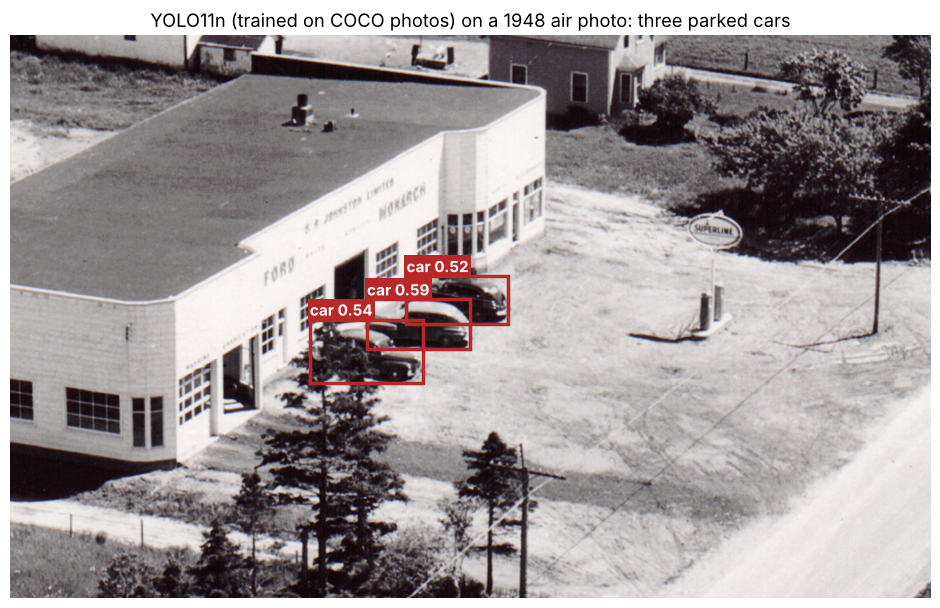

In [23]:
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.imshow(cv2.cvtColor(garage, cv2.COLOR_BGR2RGB)); ax.axis("off")
for d in dets_g:
    if d[4] >= 0.25:
        ax.add_patch(Rectangle((d[0], d[1]), d[2]-d[0], d[3]-d[1], fill=False, ec=RED, lw=2.5))
        ax.text(d[0], d[1] - 8, f"{d[5]} {d[4]:.2f}", color="white", fontsize=11, fontweight="bold",
                bbox=dict(fc=RED, ec="none", pad=1.5))
ax.set_title("YOLO11n (trained on COCO photos) on a 1948 air photo: three parked cars")
plt.tight_layout(); plt.show()

## 8 · YOLO on the cabins: right boxes, wrong label

COCO has no "cabin" or "house" class. What does YOLO do with the court?

In [24]:
dets_c = yolo_dets(yolo, cv2.cvtColor(court, cv2.COLOR_GRAY2BGR), 1408)
from collections import Counter
print("labels with score ≥ 0.25:", Counter(d[5] for d in dets_c if d[4] >= 0.25))
for d in dets_c[:5]:
    print(f"  {d[5]:6s} {d[4]:.2f}")
n, tp, p, r = pr(dets_c, GT, 0.25)
print(f"ignoring the label, score ≥ 0.25: {n} boxes, {tp} are on a cabin (IoU ≥ 0.5) "
      f"-> precision {p:.2f}, recall {r:.2f}")

labels with score ≥ 0.25: Counter({'train': 9})
  train  0.64
  train  0.61
  train  0.55
  train  0.55
  train  0.52
ignoring the label, score ≥ 0.25: 9 boxes, 9 are on a cabin (IoU ≥ 0.5) -> precision 1.00, recall 0.35


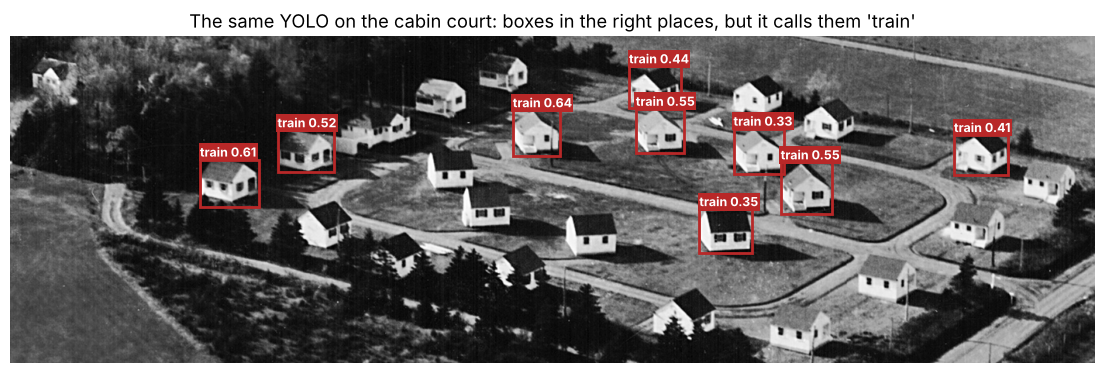

In [25]:
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.imshow(court, cmap="gray"); ax.axis("off")
for d in dets_c:
    if d[4] >= 0.25:
        ax.add_patch(Rectangle((d[0], d[1]), d[2]-d[0], d[3]-d[1], fill=False, ec=RED, lw=2))
        ax.text(d[0], d[1] - 4, f"{d[5]} {d[4]:.2f}", color="white", fontsize=9, fontweight="bold",
                bbox=dict(fc=RED, ec="none", pad=1))
ax.set_title("The same YOLO on the cabin court: boxes in the right places, but it calls them 'train'")
plt.show()

The network has learned **where objects are** (compact, bright, edged shapes with shadows) from 118,000
COCO photos, and that part transfers. Its 80 **labels** don't include cabins, so it picks the closest
thing it knows. A score of 0.64 is the network's confidence, **not** a probability that it is right.

## 9 · Fine-tuning YOLO on 12 labelled cabins (the L14 recipe for detectors)

L14's recipe works for detectors too: start from the trained network, replace the last layer with our own
classes (here just one: `cabin`), and train briefly on a few labelled examples.

* **Training:** the left part of the court (x < 712): 12 cabins.
* **Test:** the right part (x ≥ 712): 14 cabins the network never sees during training.

`ultralytics` wants images plus one text file per image with a line `class cx cy w h` (all divided by the
image size; §1) per object.

In [26]:
SPLIT = 712
root = os.path.abspath("cabins_yolo")
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
    os.makedirs(f"{root}/{sub}", exist_ok=True)

def write_part(part, x0, x1):
    img = cv2.cvtColor(court[:, x0:x1], cv2.COLOR_GRAY2BGR); h, w = img.shape[:2]
    cv2.imwrite(f"{root}/images/{part}/{part}.png", img)
    lines = []
    for b in GT:
        if b[0] >= x0 and b[2] <= x1:
            cx, cy, bw, bh = corners_to_cxcywh(b - np.array([x0, 0, x0, 0]))
            lines.append(f"0 {cx/w:.5f} {cy/h:.5f} {bw/w:.5f} {bh/h:.5f}")
    open(f"{root}/labels/{part}/{part}.txt", "w").write("\n".join(lines) + "\n")
    return len(lines)

print("training cabins:", write_part("train", 0, SPLIT), "| test cabins:", write_part("val", SPLIT, court.shape[1]))
open(f"{root}/data.yaml", "w").write(f"path: {root}\ntrain: images/train\nval: images/val\nnames:\n  0: cabin\n")
print(open(f"{root}/labels/train/train.txt").read().splitlines()[0], "  <- first label line")

training cabins: 12 | test cabins: 14
0 0.08146 0.11730 0.08427 0.10664   <- first label line


In [27]:
EPOCHS = int(os.environ.get("L15_EPOCHS", 150))       # about 100 s on a 2-core CPU; seconds on a Colab GPU
t = time.time()
cab = YOLO("yolo11n.pt")
cab.train(data=f"{root}/data.yaml", epochs=EPOCHS, imgsz=640, batch=4, workers=0, seed=0, deterministic=True,
          device=0 if torch.cuda.is_available() else "cpu", plots=False, verbose=False,
          project=os.path.abspath("runs_l15"), name="cabins", exist_ok=True)
print(f"fine-tuned {EPOCHS} epochs in {time.time()-t:.0f} s")
cab = YOLO(os.path.abspath("runs_l15/cabins/weights/best.pt"))

fine-tuned 150 epochs in 102 s


In [28]:
right = cv2.cvtColor(court[:, SPLIT:], cv2.COLOR_GRAY2BGR)
GT_r = np.array([b - np.array([SPLIT, 0, SPLIT, 0]) for b in GT if b[0] >= SPLIT])
dets_ft = yolo_dets(cab, right, 640)
print(" thr   boxes  TP   precision  recall    (14 test cabins)")
for thr in [0.7, 0.5, 0.25, 0.1]:
    n, tp, p, r = pr(dets_ft, GT_r, thr)
    print(f"{thr:4.2f}  {n:5d}  {tp:3d}   {p:8.2f}  {r:6.2f}")

 thr   boxes  TP   precision  recall    (14 test cabins)
0.70      8    7       0.88    0.50
0.50     10    9       0.90    0.64
0.25     18   12       0.67    0.86
0.10     36   14       0.39    1.00


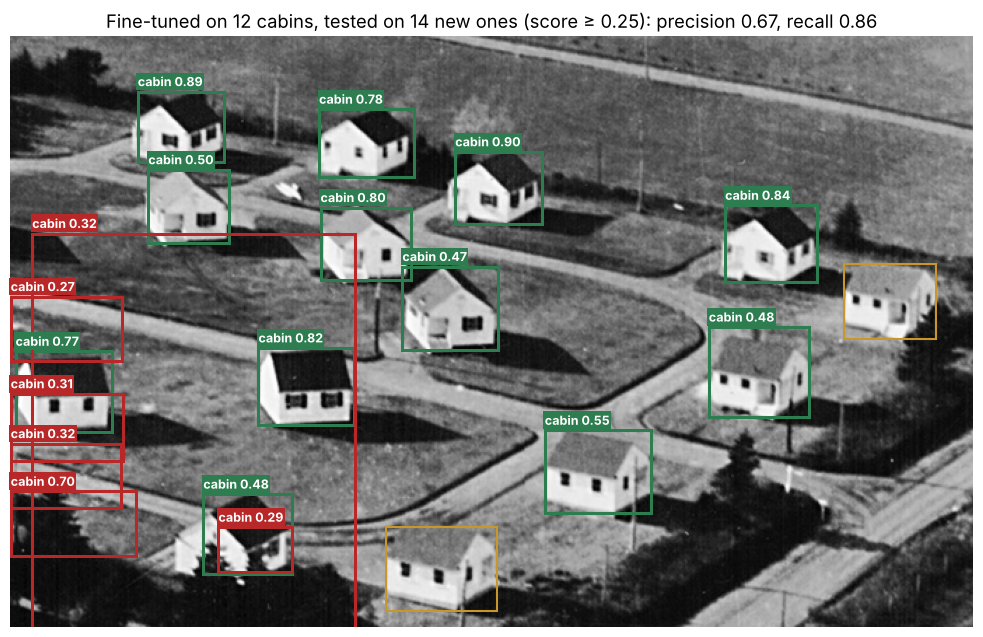

In [29]:
THR_FT = 0.25
flags, missed = match(dets_ft, GT_r, THR_FT)
kept = [d for d in dets_ft if d[4] >= THR_FT]
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.imshow(right[:, :, 0], cmap="gray"); ax.axis("off")
for d, f in zip(kept, flags):
    col = GREEN if f else RED
    ax.add_patch(Rectangle((d[0], d[1]), d[2]-d[0], d[3]-d[1], fill=False, ec=col, lw=2.2))
    ax.text(d[0], d[1] - 4, f"cabin {d[4]:.2f}", color="white", fontsize=9, fontweight="bold",
            bbox=dict(fc=col, ec="none", pad=1))
draw_boxes(ax, GT_r[missed], GOLD, 1.5)
n, tp, p, r = pr(dets_ft, GT_r, THR_FT)
ax.set_title(f"Fine-tuned on 12 cabins, tested on 14 new ones (score ≥ {THR_FT}): "
             f"precision {p:.2f}, recall {r:.2f}")
plt.tight_layout(); plt.show()

## 10 · The three detectors side by side

All three on the same **test half** (14 cabins, x ≥ 712). The template (cabin 22) and the 12 training cabins
all come from the left half, so nothing here has seen the test cabins.

In [30]:
res_r = cv2.matchTemplate(court[:, SPLIT:], T, cv2.TM_CCOEFF_NORMED)
ys, xs = np.where(res_r >= 0.3); sc = res_r[ys, xs]
bx = np.stack([xs, ys, xs + tw, ys + th], 1)
k = np.array(cv2.dnn.NMSBoxes([[int(a), int(b), tw, th] for a, b, _, _ in bx], sc.tolist(), 0.3, 0.3)).ravel()
dets_tm_r = sorted([(*bx[i], sc[i]) for i in k], key=lambda d: -d[4])
dets_coco_r = yolo_dets(yolo, right, 704)

rows = [("template matching (1 example cabin)", dets_tm_r, 0.40),
        ("YOLO11n, COCO weights (label ignored)", dets_coco_r, 0.25),
        (f"YOLO11n fine-tuned on 12 cabins", dets_ft, 0.25)]
print(f"{'detector':40s} {'thr':>5s} {'boxes':>6s} {'TP':>4s} {'P':>6s} {'R':>6s} {'AP':>6s}")
summary = []
for name, d, thr in rows:
    n, tp, p, r = pr(d, GT_r, thr)
    rc, pc, _ = pr_curve(d, GT_r); ap = average_precision(rc, pc)
    summary.append((name, thr, n, tp, p, r, ap))
    print(f"{name:40s} {thr:5.2f} {n:6d} {tp:4d} {p:6.2f} {r:6.2f} {ap:6.2f}")

detector                                   thr  boxes   TP      P      R     AP
template matching (1 example cabin)       0.40     14   10   0.71   0.71   0.72
YOLO11n, COCO weights (label ignored)     0.25      6    6   1.00   0.43   0.70
YOLO11n fine-tuned on 12 cabins           0.25     18   12   0.67   0.86   0.91


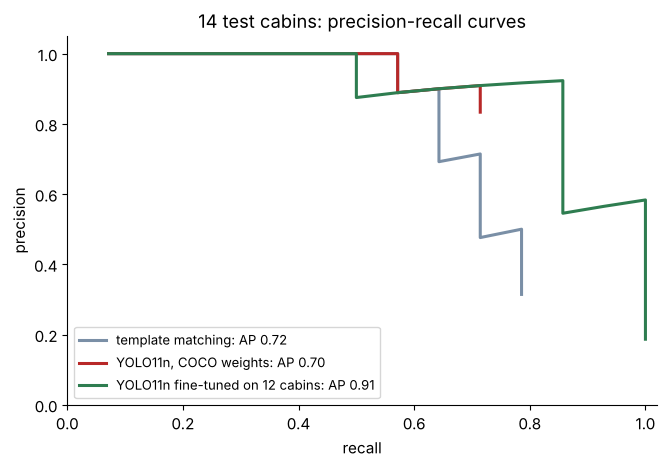

In [31]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))
for (name, d, thr), col in zip(rows, [GREY, RED, GREEN]):
    rc, pc, _ = pr_curve(d, GT_r)
    ax.plot(rc, pc, color=col, lw=2.2, label=f"{name.split(' (')[0]}: AP {average_precision(rc, pc):.2f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.legend(loc="lower left", fontsize=9.5)
ax.set_title("14 test cabins: precision-recall curves")
plt.tight_layout(); plt.show()

Twelve labelled cabins and two minutes of training turned a network that called cabins "trains" into a
cabin detector. That is the recipe for AL9 and for the building-identification project: **draw boxes on a few
dozen examples, fine-tune a small YOLO, and measure precision and recall on photos it has not seen.**
With one photo and 14 test cabins these numbers are rough (one cabin = 7 points of recall).

## 11 · Try at home

**A. IoU and NMS by hand.** A = (10, 10, 30, 30), B = (20, 20, 40, 40), C = (12, 10, 32, 30), scores
0.9, 0.7, 0.8. Compute the three IoUs, then run NMS at 0.5 by hand. Check with `iou` and `nms`.

**B. Two templates.** Cabins facing left and right look different. Run `matchTemplate` with cabin 22 *and* a
cabin facing the other way, put all boxes together, then run NMS once. Does recall go up?

**C. More or fewer labels.** Fine-tune on only 6 training cabins (delete lines from the label file), and on
all 12 with `epochs=50`. How do precision and recall change?

**D. Your own photo.** Run `yolo_dets(yolo, cv2.imread("your_photo.jpg"), 640)` on a phone photo of a street
or a parking lot. Which classes come up? Which objects does it miss?

**E. The far cabins.** `L15/cabins_1950.jpg` also shows a row of small cabins at the top. Run the fine-tuned
model on it. Do the small cabins get found? (Hint: the network only saw cabins about 60 px wide.)

In [32]:
# Try at home A: check your hand answers
A, Bx, C = (10, 10, 30, 30), (20, 20, 40, 40), (12, 10, 32, 30)
print(f"IoU(A,B) {iou(A, Bx):.3f}  IoU(A,C) {iou(A, C):.3f}  IoU(B,C) {iou(Bx, C):.3f}")
print("NMS keeps:", ["ABC"[k] for k in nms(np.array([A, Bx, C]), np.array([0.9, 0.7, 0.8]), 0.5)])

IoU(A,B) 0.143  IoU(A,C) 0.818  IoU(B,C) 0.176
NMS keeps: ['A', 'B']
